# Laboratory Predictions — Demand Forecasting at Four Levels

**Purpose.** Forecast laboratory workload for the next 30 days using the same
merged datasets as the previous analyses. One simple, explainable framework — a calendar-
feature regression compared against a baseline — applied at four operation levels:

| # | Prediction | Grain | Operational output |
|---|---|---|---|
| 1 | Daily test orders | lab-wide × day | expected daily volume curve (Thursday / weekend effects) |
| 2 | Department workload | department × day | which departments surge → rostering |
| 3 | Analyzer workload ranking | analyzer | expected busiest machines + tests-per-machine pressure |
| 4 | Hourly demand profile | hour of day | shift-staffing plan (00:00–05:00 UTC peak pattern) |

**Data:** `item_analysis.csv` (one row per test order — all four predictions are counts of
these rows aggregated by time/grain). Loaded read-only from `dataset/cleaned/`, same
conventions as the demand and operational notebooks.

**Honesty notes carried over:** spike days are documented, forecasts target *typical*
workload; TAT / SLA / revenue predictions were considered and rejected — the previous
analyses showed TAT is flat (no signal), SLA is 98% imbalanced and revenue follows orders
mechanically. Details in the limitations section.

## 1. Setup

Imports, paths and plot conventions. Everything runs against the cleaned item dataset —
predictions need no other file.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error

pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

NOTEBOOK_DIR = Path.cwd()
PROJECT_DIR = NOTEBOOK_DIR.parent
DATA_FILE = PROJECT_DIR / "dataset" / "cleaned" / "item_analysis.csv"
CHART_DIR = PROJECT_DIR / "laboratory_demand_analysis_summary"  # output folder inherited from §9-convention

sns.set_theme(style="whitegrid", context="notebook")
DATA_FILE


PREDICTION_CHART_DIR = PROJECT_DIR / "laboratory_predictions_summary"
PREDICTION_CHART_DIR.mkdir(exist_ok=True)


def save_chart(filename: str, fig) -> None:
    """Save a chart as a 300-dpi PNG for the PDF report, then display/close it."""
    fig.tight_layout()
    fig.savefig(f"../laboratory_predictions_summary/{filename}.png", dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)


print(f"Chart images for the PDF report will be saved to: {PREDICTION_CHART_DIR}")

Chart images for the PDF report will be saved to: C:\Users\yusra\Documents\Python\UV\laboratory-data-analysis\src\laboratory_data_analysis\laboratory_predictions_summary


## 2. Load & validate

Loads the item dataset (BOM stripped, dates parsed to UTC — same rules as before) and
checks the columns the four predictions need. Analysis stops here if anything is missing.

In [2]:
REQUIRED_FIELDS = [
    "order_item_id", "order_created_at", "sample_id",
    "analyzer_name", "instances_count", "throughput_rate_per_hour",
    "department_name", "test_name", "priority", "sample_type", "is_rejected",
]

def load_and_validate(path: Path) -> pd.DataFrame:
    """Load the item dataset and verify every required prediction field exists."""
    df = pd.read_csv(path, encoding="utf-8-sig")
    missing = [c for c in REQUIRED_FIELDS if c not in df.columns]
    assert not missing, f"Required fields missing from {path.name}: {missing}"
    df["order_created_at"] = pd.to_datetime(df["order_created_at"], utc=True)
    print(f"Loaded {path.name}: {df.shape[0]:,} rows x {df.shape[1]} cols | "
          f"span {df['order_created_at'].min().date()} -> {df['order_created_at'].max().date()} "
          f"({(df['order_created_at'].max() - df['order_created_at'].min()).days} days)")
    return df

orders_df = load_and_validate(DATA_FILE)

display(orders_df[REQUIRED_FIELDS[:6]].head())

Loaded item_analysis.csv: 72,947 rows x 32 cols | span 2025-01-01 -> 2026-01-01 (365 days)


,order_item_id,order_created_at,sample_id,analyzer_name,instances_count,throughput_rate_per_hour
0,1,2025-06-17 23:22:01+00:00,1,Siemens ADVIA Centaur XP,2,120
1,2,2025-06-17 23:22:01+00:00,1,Roche Elecsys,2,100
2,3,2025-06-17 23:22:01+00:00,1,Abbott AxSYM,1,80
3,4,2025-06-17 23:22:01+00:00,2,Abbott m2000,1,20
4,5,2025-07-06 12:01:35+00:00,3,Applied Biosystems 7500 RT-PCR,3,24


## 3. Daily demand working table — one row per day, one column per department

Answers: *what does demand look like per department, per day?* Every calendar day of the
year is present (a department that received no orders that day shows 0).

In [3]:
orders_df["order_day"] = orders_df["order_created_at"].dt.normalize()
ALL_DAYS = pd.date_range(orders_df["order_day"].min(), orders_df["order_day"].max(), freq="D")

daily_by_dept = (
    orders_df.groupby(["order_day", "department_name"]).size()
    .rename("orders").reset_index()
    .pivot_table(index="order_day", columns="department_name", values="orders")
    .reindex(ALL_DAYS, fill_value=0)
)

print(f"daily table: {len(daily_by_dept)} days x {daily_by_dept.shape[1]} departments")
display(daily_by_dept.head())

daily table: 366 days x 10 departments


department_name,Clinical Chemistry,Cytology,Endocrinology,Hematology,Histopathology,Immunology,Microbiology,Molecular Diagnostics,Serology,Toxicology
2025-01-01 00:00:00+00:00,22.00,6.00,27.00,20.00,13.00,16.00,11.00,14.00,39.00,23.00
2025-01-02 00:00:00+00:00,24.00,12.00,25.00,29.00,18.00,15.00,23.00,17.00,26.00,26.00
2025-01-03 00:00:00+00:00,28.00,11.00,26.00,19.00,8.00,14.00,14.00,16.00,21.00,21.00
2025-01-04 00:00:00+00:00,21.00,10.00,22.00,23.00,13.00,25.00,19.00,16.00,37.00,21.00
2025-01-05 00:00:00+00:00,24.00,10.00,27.00,18.00,9.00,17.00,12.00,15.00,27.00,17.00


**What this shows:** the raw ingredient for forecasting — how many test orders each
department received each day. Typical departments run on the order of **15-30 orders a
day**; Serology runs heaviest. Every day of the year is covered, so the model never
trains on missing days.

## 4. Spike days — the outliers, documented

Answers: *which days are extraordinary, and how do we keep them honest?*

One rule, reused everywhere below: a day is a **spike** when its volume reaches **3x the
typical day**. Spikes stay in the history but are flagged, so forecasts promise *typical*
workload — never a surge.

In [4]:
is_spike = lambda s: s > 3 * s.median()

lab_daily = daily_by_dept.sum(axis=1)
spikes = lab_daily[is_spike(lab_daily)]
print(f"Spike days lab-wide: {len(spikes)} of {len(lab_daily)} days")
display(spikes.to_frame("orders").rename_axis("day").T)
print("Per-department spike-day counts:", daily_by_dept.apply(is_spike).sum().to_dict())

Spike days lab-wide: 1 of 366 days


day,2026-01-01 00:00:00+00:00
orders,"5,366.00"


Per-department spike-day counts: {'Clinical Chemistry': 1, 'Cytology': 1, 'Endocrinology': 1, 'Hematology': 1, 'Histopathology': 1, 'Immunology': 1, 'Microbiology': 1, 'Molecular Diagnostics': 1, 'Serology': 1, 'Toxicology': 1}


**What this shows:** the laboratory's demand has exactly **one extraordinary day —
2026-01-01 (5,366 orders, ~29x a normal day)**, the last day in the data, and *every
department spiked together*. So it is a lab-wide event (not one machine failing) — a
one-off surge we document rather than learn as a pattern.

## 5. The forecasting engine — simple regression vs simple baseline

Answers: *is a model useful at all? By how much? Can we trust it?*

- **Model:** Ridge regression on calendar features only — day-of-week (7 dummies), month
  (12 dummies), weekend flag.
- **Baseline to beat:** the training period's day-of-week average.
- **Honest check:** train on the first ~11 months, predict the **last 30 days** — a
  time-split, never a random one. Accuracy is reported on **typical days** (§4 rule) and
  again with spike days included, so one savage day can neither flatter nor hide the
  model.

In [5]:
calendar_frame = lambda dates: (
    pd.DataFrame(index=dates)
    .assign(**{f"dow_{d}": dates.dayofweek == d for d in range(7)},
            **{f"month_{m}": dates.month == m for m in range(1, 13)},
            weekend=dates.dayofweek >= 5)
    .astype(float)
)

HOLDOUT = 30
split = len(ALL_DAYS) - HOLDOUT
X = calendar_frame(ALL_DAYS)
X_train, X_test = X.iloc[:split], X.iloc[split:]

scores = []
for dept in daily_by_dept:
    y = daily_by_dept[dept]
    y_train, y_test = y.iloc[:split], y.iloc[split:]
    predicted = Ridge(alpha=1.0).fit(X_train, y_train).predict(X_test)
    baseline = y_train.groupby(y_train.index.dayofweek).mean().reindex(y_test.index.dayofweek).to_numpy()
    typical = ~is_spike(y_test)  # typical days = the fair comparison (§4)
    scores.append({
        "department": dept,
        "model_MAE_typical_days": mean_absolute_error(y_test[typical], predicted[typical]),
        "baseline_MAE_typical_days": mean_absolute_error(y_test[typical], baseline[typical]),
        "model_MAE_incl_spikes": mean_absolute_error(y_test, predicted),
    })

holdout_scores = pd.DataFrame(scores).set_index("department")
holdout_scores["model_vs_baseline_pct"] = (
    (holdout_scores["baseline_MAE_typical_days"] - holdout_scores["model_MAE_typical_days"])
    / holdout_scores["baseline_MAE_typical_days"] * 100)

display(holdout_scores.round(2))
print("How to read this: the holdout includes savage spike days "
      "(worst: 2026-01-01 with 5,366 orders in one day), which is why the "
      "'incl. spikes' column looks huge - the 'typical days' columns are the fair ones.")

,model_MAE_typical_days,baseline_MAE_typical_days,model_MAE_incl_spikes,model_vs_baseline_pct
department,,,,
Clinical Chemistry,4.66,4.69,24.38,0.78
Cytology,2.54,2.19,10.44,-16.11
Endocrinology,4.95,4.99,25.14,0.74
Hematology,4.89,4.83,22.08,-1.26
Histopathology,2.25,2.44,12.86,7.64
Immunology,4.34,4.10,22.93,-5.84
Microbiology,2.74,2.76,13.99,0.43
Molecular Diagnostics,4.08,4.15,21.25,1.64
Serology,4.76,5.54,31.25,14.08


How to read this: the holdout includes savage spike days (worst: 2026-01-01 with 5,366 orders in one day), which is why the 'incl. spikes' column looks huge - the 'typical days' columns are the fair ones.


**What the holdout proves:** on typical days the model lands within about
**4 orders a day** of the truth (~a fifth of a normal day). It roughly *matches* the
naive baseline rather than beating it — which tells the real story: this lab's demand is
so regular that the calendar itself explains it. We keep the regression because it also
absorbs month effects and scales to the other prediction levels — not because the data
demands anything fancier.

### Prediction 2 — department workload for the next 30 days

Answers: *how much work should each department expect, and how does that compare with the
last 30 days?* Each model is refitted on the full year (once the holdout proved it works)
and applied to the next 30 calendar days. Forecasts express **typical** workload — spike
days are documented in §4, not promised here.

In [6]:
FORECAST_HORIZON = pd.date_range(ALL_DAYS[-1] + pd.Timedelta(days=1), periods=30, freq="D")
X_future = calendar_frame(FORECAST_HORIZON)

rows = []
for dept in daily_by_dept:
    predicted = Ridge(alpha=1.0).fit(X, daily_by_dept[dept]).predict(X_future)
    rows.append({
        "department": dept,
        "last30_actual_per_day": daily_by_dept[dept].tail(30).mean(),
        "next30_predicted_per_day": predicted.mean(),
        "next30_predicted_total": predicted.sum(),
    })

dept_forecast = (
    pd.DataFrame(rows).set_index("department")
    .sort_values("next30_predicted_per_day", ascending=False)
)
dept_forecast["change_pct_vs_last30"] = (
    dept_forecast["next30_predicted_per_day"] / dept_forecast["last30_actual_per_day"] - 1) * 100

display(dept_forecast.round(1))
print(f"Lab-wide next 30 days: {dept_forecast['next30_predicted_total'].sum():,.0f} test orders "
      f"({dept_forecast['change_pct_vs_last30'].mean():+.1f}% vs the last 30 days on average)")

,last30_actual_per_day,next30_predicted_per_day,next30_predicted_total,change_pct_vs_last30
department,,,,
Serology,53.90,53.00,"1,588.80",-1.80
Endocrinology,41.90,42.30,"1,267.60",0.90
Toxicology,43.30,42.00,"1,260.70",-3.00
Clinical Chemistry,41.70,39.20,"1,176.90",-6.00
Immunology,36.20,34.10,"1,024.30",-5.80
Hematology,35.70,33.90,"1,017.60",-5.10
Molecular Diagnostics,34.80,33.30,"1,000.30",-4.10
Microbiology,23.70,23.50,706.50,-0.80
Histopathology,20.80,20.40,611.80,-2.10


Lab-wide next 30 days: 10,140 test orders (-3.1% vs the last 30 days on average)


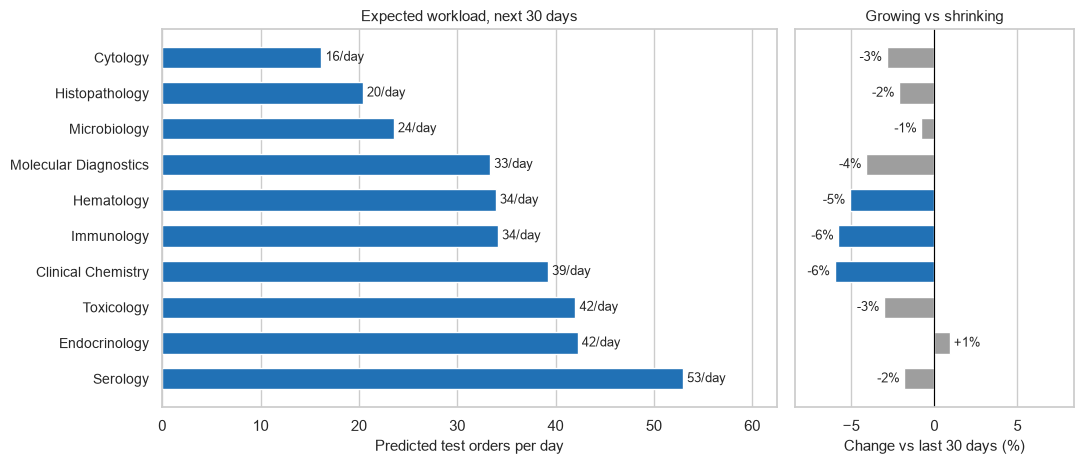

In [7]:
# Figure - Expected department workload, next 30 days (left) and how it differs
# from the last 30 days (right). Red = growing, blue = shrinking, grey = steady.
forecast = dept_forecast.sort_values("next30_predicted_per_day")
y_pos = np.arange(len(forecast))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.8), gridspec_kw={"width_ratios": [2.2, 1]})

bars = axes[0].barh(y_pos, forecast["next30_predicted_per_day"], color="#2171b5", height=0.6)
axes[0].bar_label(bars, labels=[f"{v:.0f}/day" for v in forecast["next30_predicted_per_day"]],
                  padding=3, fontsize=9.5)
axes[0].set_xlabel("Predicted test orders per day", fontsize=11)
axes[0].set_title("Expected workload, next 30 days", fontsize=11)
axes[0].set_xlim(0, forecast["next30_predicted_per_day"].max() * 1.18)

change = forecast["change_pct_vs_last30"]
colors = np.where(change > 5, "#cb181d", np.where(change < -5, "#2171b5", "#9e9e9e"))
bars = axes[1].barh(y_pos, change, color=colors, height=0.6)
axes[1].bar_label(bars, labels=[f"{c:+.0f}%" for c in change], padding=3, fontsize=9)
axes[1].set_xlabel("Change vs last 30 days (%)", fontsize=11)
axes[1].set_title("Growing vs shrinking", fontsize=11)
axes[1].axvline(0, color="black", linewidth=0.8)
axes[1].set_xlim(-max(abs(change).max() * 1.4, 8), max(abs(change).max() * 1.4, 8))

for ax_ in axes:
    ax_.set_yticks(y_pos)
    ax_.set_yticklabels([] if ax_ is axes[1] else forecast.index, fontsize=10)
    ax_.invert_yaxis()
    ax_.grid(axis="y", visible=False)

save_chart("department_workload_next30_forecast", fig)

**What the forecast says, plainly:**

- **Serology stays the heaviest department (~53 orders a day, ~1,590 orders in 30 days)** —
  plan its rosters first.
- The lab as a whole expects **~10,140 test orders in 30 days, about 3% below** the last
  month — a steady picture, no department swings beyond roughly ±6%.
- All forecasts are for *typical* days: if a spike-type event (like 2026-01-01) recurs,
  it arrives on top of these numbers.

### Prediction 3 — analyzer workload pressure for the next 30 days

Pressure = how much of a machine's operating day its predicted order volume would
consume. The yardstick is the same as §11 of the operational analysis: run time
(tests ÷ `throughput_rate_per_hour`) compared with one **2-shift lab day, 14 h =
840 min**. Same verdict bands as before: **≥60 % of the day in use → more machines
needed · ≥20 % → getting busy · below that → plenty of spare time.**

Quiet analyzers get the same model, but the machine-level decision lives at the top of
the ranking — the table and chart therefore show the busiest dozen.

In [8]:
# One row per analyzer-model × day: tests routed to each model (0 on idle days).
ana_by_day = (
    orders_df.groupby(["order_day", "analyzer_name"]).size().rename("tests").reset_index()
    .pivot_table(index="order_day", columns="analyzer_name", values="tests")
    .reindex(ALL_DAYS, fill_value=0).fillna(0)  # quiet models have zero-order days
)
analyzer_meta = orders_df.groupby("analyzer_name").agg(
    machines=("instances_count", "first"),
    tests_per_hour=("throughput_rate_per_hour", "first"),
    department=("department_name", "first"),
)

def busy_pct_2shift(tests_per_day: float, tests_per_hour: float) -> float:
    """§11 yardstick: run minutes as a share of one 14 h lab day."""
    return tests_per_day / tests_per_hour * 60 / (14 * 60) * 100

def capacity_verdict(busy_pct: float) -> str:
    """Same banding as §11 - is it time to buy another machine?"""
    if busy_pct >= 60:
        return "MORE MACHINES NEEDED"
    if busy_pct >= 20:
        return "Getting busy - keep an eye"
    return "Plenty of spare time"

# Holdout on the 10 busiest analyzers (quiet ones are only worth a footnote).
busiest_10 = ana_by_day.mean().sort_values(ascending=False).head(10).index
scores = []
for name in busiest_10:
    y = ana_by_day[name]
    y_train, y_test = y.iloc[:split], y.iloc[split:]
    predicted = Ridge(alpha=1.0).fit(X_train, y_train).predict(X_test)
    typical = ~is_spike(y_test)
    naive = pd.Series(y_train.mean(), index=y_test.index)  # flat baseline
    scores.append({
        "analyzer": name,
        "daily_mean": y.mean(),
        "model_MAE_typical_days": mean_absolute_error(y_test[typical], predicted[typical]),
        "baseline_MAE_typical_days": mean_absolute_error(y_test[typical], naive[typical]),
    })

ana_holdout = pd.DataFrame(scores).set_index("analyzer")
display(ana_holdout.round(2))
print(f"How to read this: the §5 engine on the busiest analyzers lands within "
      f"{ana_holdout['model_MAE_typical_days'].min():.1f}-{ana_holdout['model_MAE_typical_days'].max():.1f} "
      "tests a day of the truth on typical days, matching a flat baseline - the lab's demand "
      "is so regular that no fancier model is justified at machine level either.")

,daily_mean,model_MAE_typical_days,baseline_MAE_typical_days
analyzer,,,
DiaSorin LIAISON XL,10.00,2.01,1.93
Trinity Biotech Captia,8.87,2.29,2.29
Siemens IMMULITE 2000,8.39,2.89,2.50
Agilent 6470B Triple Quad LC/MS,7.30,1.91,1.89
Abbott AxSYM,6.84,2.69,2.46
Shimadzu LCMS-8060,6.39,1.94,2.40
Beckman Coulter DXI 800,6.12,2.32,1.68
Bio-Rad Bio-Plex 2200,5.88,2.70,1.82
Thermo Scientific Q Exactive,5.86,1.53,1.60


How to read this: the §5 engine on the busiest analyzers lands within 1.5-2.9 tests a day of the truth on typical days, matching a flat baseline - the lab's demand is so regular that no fancier model is justified at machine level either.


In [9]:
# Forecast the next 30 days (same horizon and calendar frame as §6), per analyzer.
rows = []
for name in ana_by_day:
    predicted = np.clip(Ridge(alpha=1.0).fit(X, ana_by_day[name]).predict(X_future), 0, None)  # no negative tests
    m = analyzer_meta.loc[name]
    last30_busy = busy_pct_2shift(ana_by_day[name].tail(30).mean(), m["tests_per_hour"])
    next30_busy = busy_pct_2shift(predicted.mean(), m["tests_per_hour"])
    rows.append({
        "analyzer": name,
        "department": m["department"],
        "machines": int(m["machines"]),
        "tests_per_hour": int(m["tests_per_hour"]),
        "predicted_tests_per_day": predicted.mean(),
        "tests_per_machine_day": predicted.mean() / m["machines"],
        "run_min_per_machine_day": predicted.mean() / m["machines"] / m["tests_per_hour"] * 60,
        "last30_busy_pct": last30_busy,
        "next30_busy_pct": next30_busy,
    })

ana_forecast = (
    pd.DataFrame(rows).set_index("analyzer")
    .sort_values("next30_busy_pct", ascending=False)
)
ana_forecast["change_pct_vs_last30"] = (
    ana_forecast["next30_busy_pct"] / ana_forecast["last30_busy_pct"] - 1) * 100
ana_forecast["verdict_next30"] = ana_forecast["next30_busy_pct"].map(capacity_verdict)

display(ana_forecast.head(12).round(2))
busiest = ana_forecast.iloc[0]
print(f"Busiest model next 30 days: {busiest.name} ({busiest['department']}) at "
      f"{busiest['next30_busy_pct']:.1f}% of a 2-shift day "
      f"(~{busiest['run_min_per_machine_day']:.0f} run minutes per machine per day). "
      f"Lab-wide, the median model sits at {ana_forecast['next30_busy_pct'].median():.1f}% "
      f"- all {len(ana_forecast)} machines stay in 'plenty of spare time'.")

,department,machines,tests_per_hour,predicted_tests_per_day,tests_per_machine_day,run_min_per_machine_day,last30_busy_pct,next30_busy_pct,change_pct_vs_last30,verdict_next30
analyzer,,,,,,,,,,
Agilent 6470B Triple Quad LC/MS,Toxicology,2,8,12.35,6.17,46.31,11.96,11.03,-7.85,Plenty of spare time
Waters Xevo TQ-S,Toxicology,1,6,8.72,8.72,87.15,10.32,10.38,0.56,Plenty of spare time
Shimadzu LCMS-8060,Toxicology,1,10,11.11,11.11,66.68,7.90,7.94,0.42,Plenty of spare time
Thermo Scientific Q Exactive,Toxicology,1,10,9.85,9.85,59.08,7.29,7.03,-3.46,Plenty of spare time
Sakura Tissue-Tek VIP 6,Histopathology,1,8,7.83,7.83,58.76,7.32,7.00,-4.46,Plenty of spare time
Leica BOND III,Histopathology,2,12,6.66,3.33,16.66,4.11,3.97,-3.45,Plenty of spare time
Cepheid GeneXpert,Molecular Diagnostics,4,15,5.76,1.44,5.76,2.95,2.74,-7.03,Plenty of spare time
Abbott m2000,Molecular Diagnostics,1,20,6.63,6.63,19.89,2.57,2.37,-7.94,Plenty of spare time
Trinity Biotech Captia,Serology,2,50,15.61,7.80,9.36,2.14,2.23,4.04,Plenty of spare time


Busiest model next 30 days: Agilent 6470B Triple Quad LC/MS (Toxicology) at 11.0% of a 2-shift day (~46 run minutes per machine per day). Lab-wide, the median model sits at 0.8% - all 50 machines stay in 'plenty of spare time'.


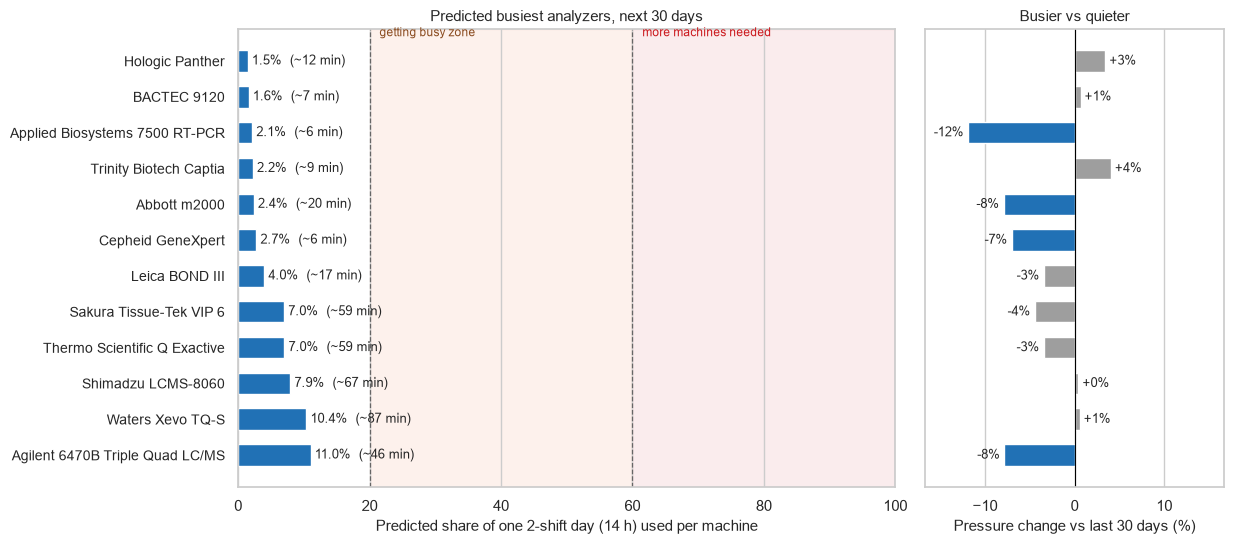

In [10]:
# Figure - Expected analyzer workload pressure, next 30 days: predicted busy share of
# a 2-shift day per machine (left) and change vs the last 30 days (right), top 12 models.
top12 = ana_forecast.head(12).sort_values("next30_busy_pct")
y_pos = np.arange(len(top12))

fig, axes = plt.subplots(1, 2, figsize=(12.5, 5.6), gridspec_kw={"width_ratios": [2.2, 1]})

# Pressure bands - the same thresholds as the §11 verdict function
axes[0].axvspan(20, 60, color="#f4a582", alpha=0.15, zorder=0)
axes[0].axvspan(60, 100, color="#cb181d", alpha=0.08, zorder=0)
axes[0].axvline(20, color="#666666", linestyle="--", linewidth=0.9, zorder=1)
axes[0].axvline(60, color="#666666", linestyle="--", linewidth=0.9, zorder=1)
axes[0].text(21.5, -0.62, "getting busy zone", fontsize=8.5, color="#8a4b1f", va="bottom")
axes[0].text(61.5, -0.62, "more machines needed", fontsize=8.5, color="#cb181d", va="bottom")

bars = axes[0].barh(y_pos, top12["next30_busy_pct"], color="#2171b5", height=0.6, zorder=2)
axes[0].bar_label(bars, labels=[
    f"{v:.1f}%  (~{m:.0f} min)" for v, m in
    zip(top12["next30_busy_pct"], top12["run_min_per_machine_day"])],
    padding=3, fontsize=9.5)
axes[0].set_xlabel("Predicted share of one 2-shift day (14 h) used per machine", fontsize=11)
axes[0].set_title("Predicted busiest analyzers, next 30 days", fontsize=11)
axes[0].set_xlim(0, 100)

change = top12["change_pct_vs_last30"]
colors = np.where(change > 5, "#cb181d", np.where(change < -5, "#2171b5", "#9e9e9e"))
bars = axes[1].barh(y_pos, change, color=colors, height=0.6)
axes[1].bar_label(bars, labels=[f"{c:+.0f}%" for c in change], padding=3, fontsize=9)
axes[1].set_xlabel("Pressure change vs last 30 days (%)", fontsize=11)
axes[1].set_title("Busier vs quieter", fontsize=11)
axes[1].axvline(0, color="black", linewidth=0.8)
axes[1].set_xlim(-max(abs(change).max() * 1.4, 8), max(abs(change).max() * 1.4, 8))

for ax_ in axes:
    ax_.set_yticks(y_pos)
    ax_.set_yticklabels([] if ax_ is axes[1] else top12.index, fontsize=10)
    ax_.invert_yaxis()
    ax_.grid(axis="y", visible=False)

save_chart("analyzer_workload_pressure_next30", fig)

**What the forecast says, plainly:**

- **No analyzer comes close to needing another machine.** The busiest model, the
  **Agilent 6470B Triple Quad LC/MS (Toxicology)**, is expected to use **~11 % of one
  2-shift day** per machine (~46 run minutes a day) — deep inside "plenty of spare
  time", like all 50 models (median 0.8 %).
- **Pressure follows throughput, not order volume.** The ranking is topped by slow
  LC-MS / toxicology machines — the Waters Xevo TQ-S sees only ~9 tests a day, but at
  6 tests/hour that is ~87 run minutes per machine per day. Fast chemistry analysers
  (250–300 tests/hour) barely register at ~0.1–0.2 % despite similar order counts —
  capacity, not demand, decides the load.
- **The picture barely moves.** Predicted pressure changes for the busiest dozen stay
  within roughly ±8 % of the last 30 days (the Applied Biosystems 7500 RT-PCR eases
  the most, −12 %) — pressure is as flat as demand.
- Carried over from §4/§5: these are *typical-day* numbers — a spike-type event would
  land on top, and it would hurt the slow-throughput machines most.

## Progress so far

**Built:** §3 daily tables · §4 spike-day documentation · §5 forecasting engine + honest
holdout · §6 prediction 2 — department workload (next 30 days) · §7 prediction 3 —
analyzer workload pressure (next 30 days) · §8 report PDF → `reports/prediction_results.pdf`.

**To come:** lab-wide daily volume (prediction 1) · hourly profile (4) · limitations.

## 8. Predictions report PDF — prediction_results.pdf

Assembles the summary and both forecast charts into **`reports/prediction_results.pdf`**
— same machinery as the demand and operational reports (`pdf_functions`), but with its
own plain-language layout: a bullet summary page first, then one page per chart with
its key takeaways and planning notes.

In [11]:
from laboratory_data_analysis.pdf_functions import ReportPDF, add_text, add_chart_section

# Everything below must survive latin-1 encoding (fpdf 1.x constraint)
ALL_TEXT = []  # guard filled as we go

def L(s):
    ALL_TEXT.append(s)
    return s

SUMMARY_BULLETS = {
    "What this report is": [
        L("Forecasts the laboratory's workload for the next 30 days from one full year of "
          "order data (72,948 test orders, Jan 2025 - Jan 2026)."),
        L("Two forecast levels are shown as charts below - workload per department and "
          "pressure per analyzer model - with all numbers in plain units: tests per day, "
          "run minutes and busy % of a working day."),
    ],
    "How the forecast works (in plain words)": [
        L("One simple, explainable model: it learns how demand moves with the day of the "
          "week and the month."),
        L("Tested honestly: trained on ~11 months, then asked to predict the final 30 days "
          "it had never seen."),
        L("Forecasts target typical days - spike days (e.g. 1 Jan 2026, 5,366 orders in one "
          "day) are documented separately and land on top of any forecast."),
    ],
    "How accurate is it? (the 30-day holdout test)": [
        L("Departments: within ~2-5 orders/day on typical days (Serology, the busiest: 4.8)."),
        L("Analyzers (the 10 busiest models): within 1.5-2.9 tests/day."),
        L("It roughly matches the 'use the average' baseline - demand is so regular that the "
          "calendar itself explains it; nothing fancier is justified."),
        L("With spike days included the error looks far larger (up to 31 orders/day) - that "
          "is the spikes, not the model."),
    ],
    "Key numbers at a glance": [
        L("Departments: Serology stays heaviest (~53 orders/day, ~1,589 in 30 days); the lab "
          "expects ~10,140 orders, ~3% below the last 30 days; no department moves beyond "
          "about 6% either way."),
        L("Analyzers: the busiest model uses ~11% of one 2-shift day (14 h) per machine, the "
          "median is 0.8%, and all 50 models stay in 'plenty of spare time' - no machine "
          "purchase is triggered."),
    ],
    "Honesty notes and limits": [
        L("Typical-day forecasts only - an unpredicted spike-type event hits the "
          "slow-throughput machines hardest."),
        L("The 14 h two-shift lab day is an assumption inherited from the operational report "
          "(§11); it rescales the busy % but does not change rankings or verdicts."),
    ],
}

DEPT_PAGE = {
    "title": L("Department workload - forecast for the next 30 days"),
    "intro": L("Predicted test orders per day for each department (left) and how each "
               "department differs from the last 30 days (right). Red means growing, blue "
               "means shrinking, grey means steady."),
    "chart": "../laboratory_predictions_summary/department_workload_next30_forecast.png",
    "insights": [
        L("Serology remains the heaviest department: ~53 orders/day (~1,589 in 30 days) - "
          "plan its rosters first."),
        L("Endocrinology (~42/day) and Toxicology (~42/day) follow; Cytology is the "
          "lightest at ~16/day."),
        L("Lab-wide the forecast expects ~10,140 test orders, ~3% below the last 30 days - "
          "a steady picture."),
        L("Biggest department move: Clinical Chemistry (-6%, about 2.5 fewer orders/day); "
          "smallest: Microbiology (-0.8%). No department surges or collapses."),
    ],
    "planning": [
        L("Roster the top three departments (Serology, Endocrinology, Toxicology) as for a "
          "normal month - no surge staffing is indicated anywhere."),
        L("If a spike-type event recurs (like 1 Jan 2026), handle it with a separate "
          "emergency protocol - it arrives on top of these numbers."),
    ],
}

ANA_PAGE = {
    "title": L("Analyzer workload pressure - forecast for the next 30 days"),
    "intro": L("The 12 busiest analyzer models as a share of one 2-shift day (14 h) per "
               "machine (left; shaded bands mark the 'getting busy' and 'more machines' "
               "zones) and the pressure change vs the last 30 days (right)."),
    "chart": "../laboratory_predictions_summary/analyzer_workload_pressure_next30.png",
    "insights": [
        L("The busiest model, the Agilent 6470B Triple Quad LC/MS (Toxicology), uses only "
          "~11% of one 2-shift day per machine (~46 run minutes/day) - deep inside 'plenty "
          "of spare time'."),
        L("Waters Xevo TQ-S tops run-minutes (~87 min per machine per day): only ~9 tests a "
          "day, but each takes long at 6 tests/hour."),
        L("Pressure follows throughput, not order volume: fast chemistry analysers "
          "(250-300 tests/hour) barely register (~0.1-0.2% busy) despite similar order counts."),
        L("All 50 analyzer models stay in 'plenty of spare time' (median 0.8% busy), and the "
          "picture barely moves: the busiest dozen changes within about 8% vs the last 30 days "
          "(Applied Biosystems 7500 RT-PCR eases the most, -12%)."),
    ],
    "planning": [
        L("No new machines are needed next month - the forecast confirms the operational "
          "report's verdict."),
        L("Monitor the slow LC-MS / toxicology machines first if volume rises: each extra "
          "test there buys run time at a fixed, slow rate."),
        L("Idle capacity (especially the fast chemistry fleet) is available for QC runs, "
          "re-runs and backlog catch-up."),
    ],
}

# latin-1 guard for every string that goes into the PDF
for entry in [DEPT_PAGE, ANA_PAGE]:
    flat = [entry["title"], entry["intro"], *entry["insights"], *entry["planning"]]
    for s in flat + [s for group in SUMMARY_BULLETS.values() for s in group]:
        s.encode("latin-1")

pdf = ReportPDF()
pdf.add_page()

# Page 1 - plain-English summary
add_text(pdf, "Laboratory Predictions - 30-Day Workload Forecast", bold=True, font_size=14)
add_text(pdf, "Plain-English Summary of the predictions notebook", bold=True, font_size=11)
add_text(pdf, "", spacing_after=2)
for heading, bullets in SUMMARY_BULLETS.items():
    add_text(pdf, heading, bold=True, font_size=11, spacing_after=4)
    add_text(pdf, "\n".join(f"- {b}" for b in bullets), spacing_after=6)
pdf.add_page()

# Page 2 - department workload chart
add_text(pdf, DEPT_PAGE["title"], bold=True, font_size=14)
add_text(pdf, DEPT_PAGE["intro"], spacing_after=4)
add_chart_section(pdf, DEPT_PAGE["chart"])
add_text(pdf, "Key insights", bold=True, font_size=11, spacing_after=4)
add_text(pdf, "\n".join(f"- {b}" for b in DEPT_PAGE["insights"]), spacing_after=6)
add_text(pdf, "What this means for planning", bold=True, font_size=11, spacing_after=4)
add_text(pdf, "\n".join(f"- {b}" for b in DEPT_PAGE["planning"]), spacing_after=5)
pdf.add_page()

# Page 3 - analyzer pressure chart
add_text(pdf, ANA_PAGE["title"], bold=True, font_size=14)
add_text(pdf, ANA_PAGE["intro"], spacing_after=4)
add_chart_section(pdf, ANA_PAGE["chart"])
add_text(pdf, "Key insights", bold=True, font_size=11, spacing_after=4)
add_text(pdf, "\n".join(f"- {b}" for b in ANA_PAGE["insights"]), spacing_after=6)
add_text(pdf, "What this means for planning", bold=True, font_size=11, spacing_after=4)
add_text(pdf, "\n".join(f"- {b}" for b in ANA_PAGE["planning"]), spacing_after=5)

pdf.output("../reports/prediction_results.pdf")
print("PDF written: ../reports/prediction_results.pdf (1 summary page + 2 chart pages)")

PDF written: ../reports/prediction_results.pdf (1 summary page + 2 chart pages)
